# Week 7 group project: Object Recognition
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%207/Week7_Starter_Object_Recognition.ipynb)

**Your group's mission:** build a very simple app (an MVP) that does
**object recognition: finding objects in a photo, with a box and a label** on photos you take yourselves, in or outside the school, find out how
good it is, and teach the rest of the class about it.

*Question for your group: what is in the photo, where is it, and how many are there?*

**Timeline**

| Time | What |
|------|------|
| 10:45-11:30 | **Phase 1 (45 min):** take photos and come up with your MVP - no laptops needed (read sections 1 and 3 for ideas) |
| 11:30 | **Stand-up:** 3 minutes per group - your MVP idea, your photos, who does what |
| 12:00-14:30 | **Phase 2:** photos into Colab, build the MVP and make it work, ground truth, evaluation, presentation (sections 0-8) |
| 14:45-15:30 | **Presentations:** your MVP, 10 minutes per group + 3 minutes questions |

**Your presentation must explain**

1. **What the technique is** - what goes in, what comes out, what it is used for (section 1)
2. **What data processing is needed** - from a phone photo to something the model can use, and the ground truth (sections 4 and 6)
3. **What you did** - your idea, your photos, how you built your MVP (sections 3 and 5)
4. **How you evaluate it** - which metric, why, and your result (section 7)
5. **The end result: your MVP** - show it working, and where it fails (section 8)

**Organise your group.** You are a big group, so split the work. A split
that works: a **photo team** (collects photos, makes the ground truth), a
**build team** (runs this notebook, builds the MVP), an **evaluation team**
(chooses and calculates the metric), and a **presentation team** (slides,
demo, timing). Pick one person who keeps an eye on the clock. Share this
notebook through Google Drive so everybody can see it.

## My individual version: a bicycle counter

**Why individual:** I missed the Week 7 workshop, so I was not in one of the three research groups and have no
group photos or slides. I asked the teachers by email what to hand in instead. Until they answer, this is my
individual version of the **object recognition** brief, made with the course's own starter notebook.

**The photos:** 9 openly licensed photos from the COCO validation set (the same collection the starter uses for
its examples) that show bicycles. They were screened for people in three ways: no person is labelled in them in
COCO; the Mask R-CNN person detector found no person at a confidence of 0.3 or more; and each photo was looked at
for real people and for pictures of people (posters, frames, screens). Every photo where a **real person** might be
visible was left out (eight in total). Three of the nine kept photos contain small **graphics**: a person-shaped
safety pictogram on a warning label (135670), and artwork on a surfboard (164115) and a hanging emblem (426166) that are
too small to rule out a drawn figure. None of them is a photo of a real person, so they stay. Nine is one fewer than
the starter's "at least 10": I chose to leave out every photo where a real person might be visible. Who took each photo and its licence are in the **Photo credits** at the end.

**The question my app answers:** *how many bicycles are parked in this photo?* For a city or a school that
wants to know whether its bike parking is used, without someone walking past every rack.

**Ground truth (provisional):** the bicycle boxes drawn by COCO's human labellers, written down in
`coco_bicycle_truth.json` before my app runs. I did not count them myself yet, and in one photo (109055) the COCO
label is a single box around almost the whole picture, so these numbers are **COCO-labelled bicycles**, not a
checked count. A box from the model counts as **right** when it overlaps a COCO-labelled bicycle by at least half
(IoU 0.5).

## 0. Setup - run these cells once

The first cell is only needed for iPhone photos in HEIC format (or set the
iPhone camera to *Settings -> Camera -> Formats -> Most Compatible*). The
second cell loads the tools and some helpers:

- `upload_to("photos")` - choose photos on your laptop; they land in the folder `photos`
- `take_photo("photos", "name.jpg")` - take a photo with the laptop camera
- `load_folder("photos")` - load all photos of a folder: turned the right way up and made smaller
- `show([...])` - show pictures next to each other
- `save_result(name)` - save the picture you just made in the folder `results`, for your slides
- `download_results()` - download the folder `results` as a zip

In [ ]:
# Only needed for iPhone HEIC photos
!pip install -q pillow-heif

In [2]:
# Run, do not read
import warnings
warnings.filterwarnings("ignore")
import os, glob, base64, shutil, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import torch
import torchvision.transforms.functional as TF
torch.set_grad_enabled(False)
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass
os.makedirs("results", exist_ok=True)

def show(images, titles=None, size=3.5):
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    if len(images) == 1:
        axes = [axes]
    for k in range(len(images)):
        axes[k].imshow(images[k], cmap="gray" if images[k].ndim == 2 else None)
        axes[k].axis("off")
        if titles:
            axes[k].set_title(titles[k], fontsize=9)
    plt.show()

def save_result(name):
    # call this INSIDE the same cell, right after a picture is drawn
    plt.savefig(os.path.join("results", name), dpi=120, bbox_inches="tight")
    print("saved results/" + name)

def download_results():
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")

def upload_to(folder):
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, content in files.upload().items():
        with open(os.path.join(folder, name), "wb") as f:
            f.write(content)

def take_photo(folder, name):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    os.makedirs(folder, exist_ok=True)
    display(Javascript('''
    async function takePhoto() {
      const div = document.createElement('div');
      const button = document.createElement('button');
      button.textContent = 'Capture';
      div.appendChild(button);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.9);
    }'''))
    data_url = eval_js("takePhoto()")
    with open(os.path.join(folder, name), "wb") as f:
        f.write(base64.b64decode(data_url.split(",")[1]))
    print("saved", os.path.join(folder, name))

def load_folder(folder, max_size=1024):
    photos = {}
    for f in sorted(glob.glob(os.path.join(folder, "*"))):
        if "_mask" in os.path.basename(f):
            continue
        try:
            im = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
        except Exception:
            print("skipped (not a photo):", f)
            continue
        im.thumbnail((max_size, max_size))
        photos[os.path.basename(f)] = np.array(im)
    print(folder, ":", len(photos), "photos")
    return photos

def download_examples(folder, urls):
    os.makedirs(folder, exist_ok=True)
    for url in urls:
        target = os.path.join(folder, url.split("/")[-1])
        if not os.path.exists(target):
            urllib.request.urlretrieve(url, target)

print("Ready")

Ready


## 1. What is object recognition?

- **Classification** gives one label for the whole photo: "this is a bicycle".
- **Object detection** finds *every* object, with a **box**, a **label** and a
  **confidence** (how sure the model is, from 0 to 1). Because you know where
  each object is, you can **count**.

You have two pre-trained detectors (run the cell; it downloads them once):

| Model | What it can find | How you ask |
|-------|------------------|-------------|
| **Mask R-CNN** (trained on COCO) | 80 fixed kinds: person, bicycle, car, chair, laptop, cup, bottle, bench, dog, ... | `find(photo, ["person", "chair"])` |
| **OWLv2** (by Google) | anything you describe in words | `find(photo, ["trash bin", "bike"], model="text")` |

The **threshold** decides which boxes you keep: low = more found, more
mistakes; high = surer, but more missed.

In [3]:
# Run, do not read: two pre-trained detectors
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from transformers import pipeline
coco_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
coco_model = maskrcnn_resnet50_fpn(weights=coco_weights).eval()
COCO = [name for name in coco_weights.meta["categories"]]
text_model = pipeline("zero-shot-object-detection", model="google/owlv2-base-patch16-ensemble")

def find(picture, what, threshold=0.5, model="coco", draw=True, title=""):
    boxes = []                                    # (label, score, [x1, y1, x2, y2])
    if model == "coco":
        out = coco_model([TF.to_tensor(picture)])[0]
        for box, lab, score in zip(out["boxes"], out["labels"], out["scores"]):
            if COCO[int(lab)] in what and score >= threshold:
                boxes.append((COCO[int(lab)], float(score), box.tolist()))
    else:
        for r in text_model(Image.fromarray(picture), candidate_labels=what, threshold=threshold):
            b = r["box"]
            boxes.append((r["label"], float(r["score"]), [b["xmin"], b["ymin"], b["xmax"], b["ymax"]]))
    if draw:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.imshow(picture)
        for label, score, (x1, y1, x2, y2) in boxes:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", linewidth=2))
            ax.text(x1, y1, label + " " + str(round(score, 2)), fontsize=7, backgroundcolor="yellow")
        ax.axis("off")
        ax.set_title(title)
    return boxes

def counts(boxes, what):
    result = {}
    for w in what:
        result[w] = sum(1 for b in boxes if b[0] == w)
    return result

print("COCO knows:", [n for n in COCO if n not in ("__background__", "N/A")])

COCO knows: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


## 2. Try it now

One example photo, both models. This is already a tiny MVP: a photo in, boxes
and counts out.

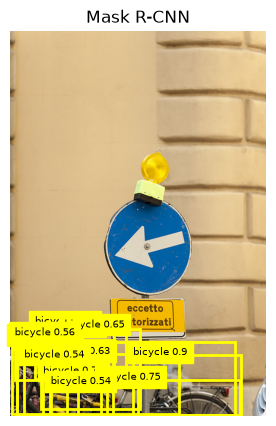

{'bicycle': 13}


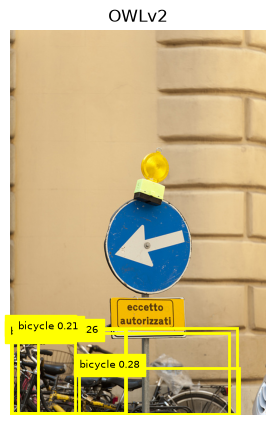

{'bicycle': 6}


In [4]:
# One of my photos, both models (instead of the starter's street photo, which has people in it)
example = np.array(Image.open(urllib.request.urlopen("http://images.cocodataset.org/val2017/000000185157.jpg")).convert("RGB"))
boxes = find(example, ["bicycle"], 0.5, title="Mask R-CNN")
plt.show()
print(counts(boxes, ["bicycle"]))
boxes = find(example, ["bicycle"], 0.2, model="text", title="OWLv2")
plt.show()
print(counts(boxes, ["bicycle"]))


## 3. Your photos

**Ideas** (or think of your own):

- *Free seats:* count chairs and people in the study area or the canteen
- *Bike shed:* how many bicycles are parked, and is it full?
- *Litter patrol:* count bottles, cans or cups left on the tables or outside
- *Green campus:* how many trees and plants are around the building?
- *Lending desk:* how many laptops are in use in a classroom?

Decide **what** your app counts, and **for whom**. Then go and take photos.

**Rules for taking photos**

- **People only with permission.** Only photograph people who say yes - accept
  a no. Other people in the school must not be recognisable: aim away, or
  photograph them from behind.
- **Never put photos of people online.** Not in your portfolio (it is public)
  and not in a shared folder outside the group. Before you upload this notebook
  anywhere: *Edit -> Clear all outputs*. Delete the photos after this week.
- **Make it hard for the model.** Different places, light, distances and
  angles, and a few difficult photos (crowded, dark, half hidden). A test with
  only easy photos tells you nothing.
- **Enough photos:** at least 10, more is better. Any phone photo works.

**Getting your photos into Colab:** `upload_to("photos")` from the laptop
(send them from your phone by AirDrop, e-mail or Google Drive first), drag a
zip into the file panel on the left and run `!unzip -q yourfile.zip -d photos`,
or use the laptop camera with `take_photo("photos", "name.jpg")`.

bike_photos : 9 photos
using 9 approved photos


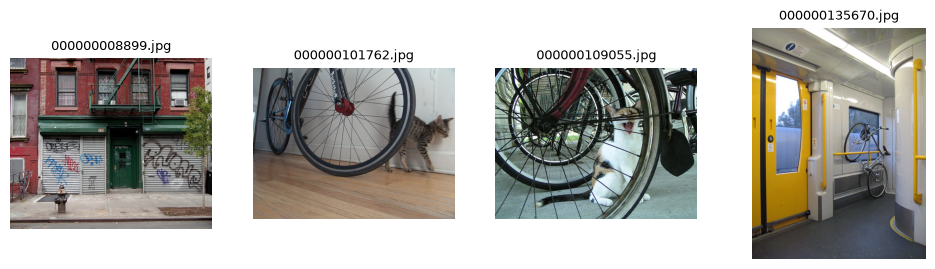

In [5]:
folder = "bike_photos"                         # its own folder; below, only the 9 approved file names are used
what = ["bicycle"]                              # the objects my app finds
model = "coco"                                  # bicycle is one of the 80 COCO objects

# 9 openly licensed COCO photos with bicycles, screened for people (credits at the end) (sources in coco_bicycle_truth.json)
download_examples(folder, ['http://images.cocodataset.org/val2017/000000008899.jpg', 'http://images.cocodataset.org/val2017/000000101762.jpg', 'http://images.cocodataset.org/val2017/000000109055.jpg', 'http://images.cocodataset.org/val2017/000000135670.jpg', 'http://images.cocodataset.org/val2017/000000164115.jpg', 'http://images.cocodataset.org/val2017/000000185157.jpg', 'http://images.cocodataset.org/val2017/000000242287.jpg', 'http://images.cocodataset.org/val2017/000000274687.jpg', 'http://images.cocodataset.org/val2017/000000426166.jpg'])

approved = ['000000008899.jpg', '000000101762.jpg', '000000109055.jpg', '000000135670.jpg', '000000164115.jpg', '000000185157.jpg', '000000242287.jpg', '000000274687.jpg', '000000426166.jpg']
photos = {name: p for name, p in load_folder(folder).items() if name in approved}   # only the approved photos
print("using", len(photos), "approved photos")
show([photos[n] for n in photos][:4], list(photos)[:4], size=3)


## 4. Data processing

A phone photo is not ready for a model. Run the cell: it shows what happens to
one of your photos on its way in. **Use this for part 2 of your
presentation.**

1. the file from the phone:      640 x 539 pixels, RGB
2. turned the right way up:      no rotation needed (phones store the rotation separately, in the EXIF data)
3. made smaller (max 1024):      640 x 539 pixels
4. a grid of numbers:            (539, 640, 3) = 1034880 numbers from 0 to 255
5. scaled to 0-1 for the model:  0.0 to 1.0


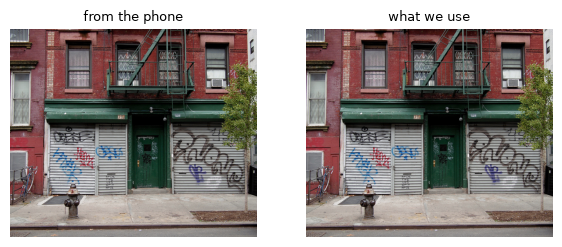

In [6]:
# Run, do not read: what happens to a phone photo before the model sees it
name = list(photos)[0]
original = Image.open(glob.glob(os.path.join(folder, name))[0])
print("1. the file from the phone:     ", original.size[0], "x", original.size[1], "pixels,", original.mode)
upright = ImageOps.exif_transpose(original)
print("2. turned the right way up:     ", "yes" if upright.size != original.size else "no rotation needed",
      "(phones store the rotation separately, in the EXIF data)")
print("3. made smaller (max 1024):     ", photos[name].shape[1], "x", photos[name].shape[0], "pixels")
print("4. a grid of numbers:           ", photos[name].shape, "=", photos[name].size, "numbers from 0 to 255")
x = TF.to_tensor(photos[name])
print("5. scaled to 0-1 for the model: ", round(float(x.min()), 2), "to", round(float(x.max()), 2))
show([np.array(original.convert("RGB")), photos[name]], ["from the phone", "what we use"])

**For object recognition, the ground truth is a count per photo** (section 6):
you count the objects yourself, before you look at the model. For a full
evaluation you also judge every box the model draws: right or wrong.

## 5. Your MVP

An MVP is the smallest thing that is useful: a photo in, an answer out. Change
`my_app` so it answers **your** question in a sentence, then run it on all
your photos. Try a few thresholds first and pick one.

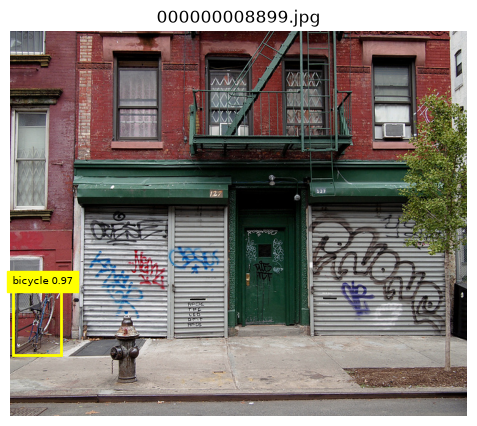

000000008899.jpg -> 1 bicycle parked here.


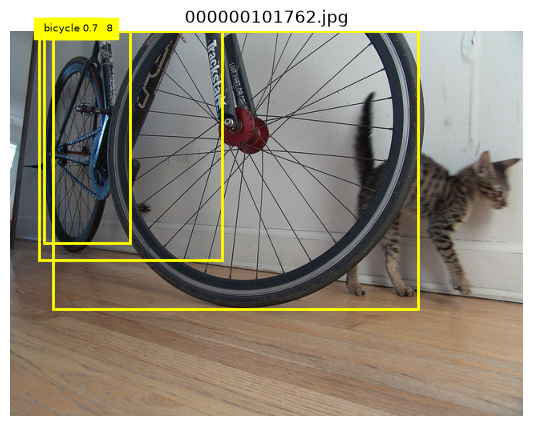

000000101762.jpg -> 3 bicycles parked here.


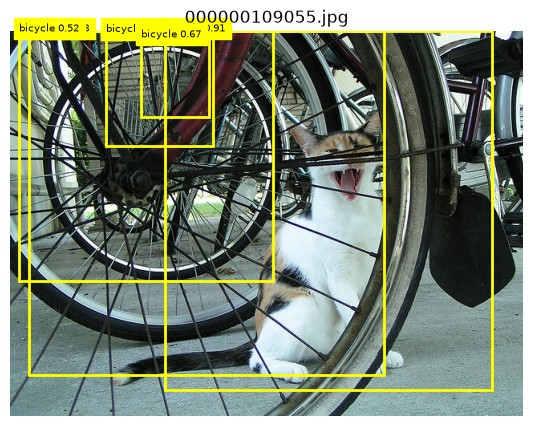

000000109055.jpg -> 5 bicycles parked here.


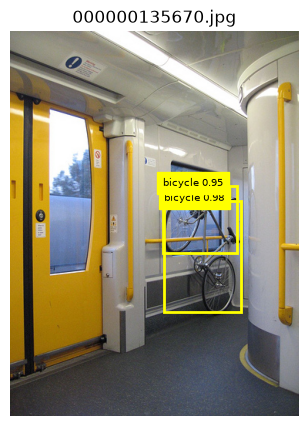

000000135670.jpg -> 2 bicycles parked here.


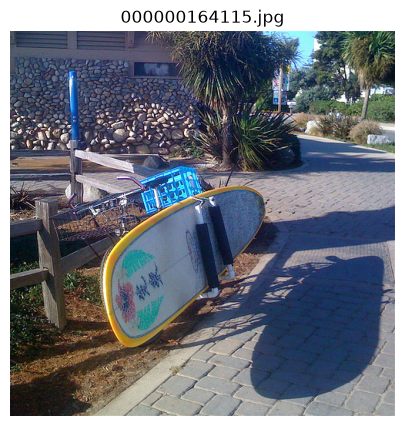

000000164115.jpg -> No bicycles found.


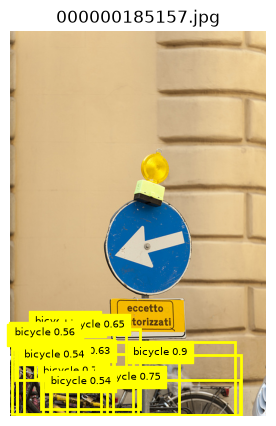

000000185157.jpg -> 13 bicycles parked here.


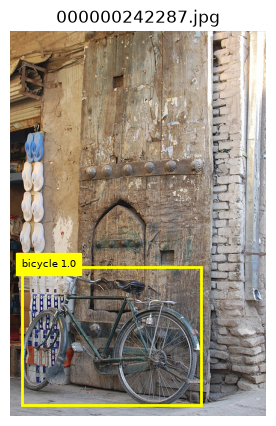

000000242287.jpg -> 1 bicycle parked here.


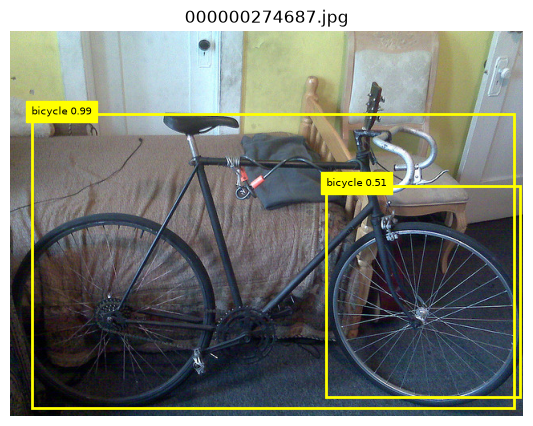

000000274687.jpg -> 2 bicycles parked here.


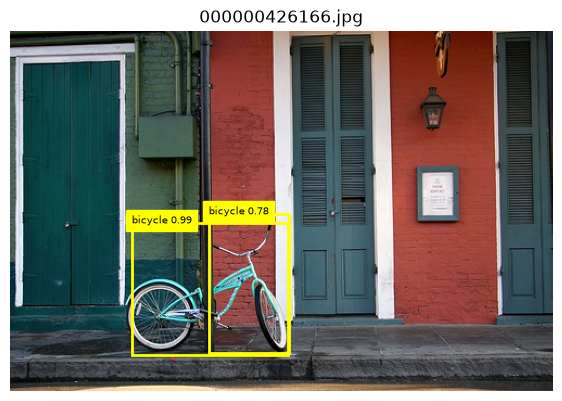

000000426166.jpg -> 2 bicycles parked here.


In [7]:
threshold = 0.5                                 # the starter's default, kept fixed (see section 7)

def my_app(picture, name=""):
    boxes = find(picture, what, threshold, model=model, title=name)
    n = counts(boxes, what)["bicycle"]
    if n == 0:
        return "No bicycles found."
    if n == 1:
        return "1 bicycle parked here."
    return str(n) + " bicycles parked here."

for name in photos:
    answer = my_app(photos[name], name)
    plt.show()
    print(name, "->", answer)


## 6. Ground truth

Count the objects in every photo **yourself** - before you trust the model -
and write it in `truth`. Agree first on what counts (half outside the photo?
hidden behind something?).

Then look at the model's boxes from section 5 and count, per photo, how many
of its boxes were **right** (a box on a real object of that kind). Write that
in `correct`. Use the exact file names.

In [8]:
import json

# Ground truth (provisional): the bicycle boxes drawn by COCO's human labellers, saved before my app runs
labels = json.load(open("coco_bicycle_truth.json"))
truth = {name: {"bicycle": len(labels[name]["bicycle_boxes"])} for name in photos}

def iou(a, b):
    # overlap of two boxes / their combined area (1 = the same box, 0 = no overlap)
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

def judge(boxes, true_boxes):
    # a model box is right when it overlaps a labelled bicycle by IoU >= 0.5; each bicycle counts once
    unused = list(true_boxes)
    right = 0
    for label, score, box in sorted(boxes, key=lambda b: -b[1]):
        best = max(unused, key=lambda t: iou(box, t), default=None)
        if best is not None and iou(box, best) >= 0.5:
            right = right + 1
            unused.remove(best)
    return right

# how many of the model's boxes were right, at my threshold
correct = {}
for name in photos:
    boxes = find(photos[name], what, threshold, model=model, draw=False)
    correct[name] = {"bicycle": judge(boxes, labels[name]["bicycle_boxes"])}

print("COCO-labelled bicycles:", sum(truth[n]["bicycle"] for n in truth), "in", len(truth), "photos")
for name in truth:
    print(name, " COCO-labelled:", truth[name]["bicycle"], " right boxes:", correct[name]["bicycle"])


COCO-labelled bicycles: 14 in 9 photos
000000008899.jpg  COCO-labelled: 1  right boxes: 1
000000101762.jpg  COCO-labelled: 1  right boxes: 1
000000109055.jpg  COCO-labelled: 1  right boxes: 1
000000135670.jpg  COCO-labelled: 1  right boxes: 1
000000164115.jpg  COCO-labelled: 1  right boxes: 0
000000185157.jpg  COCO-labelled: 6  right boxes: 3
000000242287.jpg  COCO-labelled: 1  right boxes: 1
000000274687.jpg  COCO-labelled: 1  right boxes: 1
000000426166.jpg  COCO-labelled: 1  right boxes: 1


## 7. Evaluate

Three numbers per kind of object:

- **Precision** = right boxes / all boxes the model drew - *how many false alarms?*
- **Recall** = right boxes / objects that are really there - *how many missed?*
- **Count error** = on average, how many off per photo - *what the user notices*

The second cell tries other thresholds: which one gives the smallest count
error?

In [9]:
# Run, do not read  (one fix: 'right' is now judged at the threshold you ask for, not always at 0.5)
found = {}
for name in truth:
    found[name] = find(photos[name], what, 0.0, model=model, draw=False)   # every box, any confidence

def evaluate(threshold, verbose=True):
    total = {}
    for w in what:
        kept = {n: [b for b in found[n] if b[0] == w and b[1] >= threshold] for n in truth}
        drawn = sum(len(kept[n]) for n in truth)
        real = sum(truth[n][w] for n in truth)
        errors = [abs(len(kept[n]) - truth[n][w]) for n in truth]
        total[w] = float(np.mean(errors))
        if verbose:
            right = sum(judge(kept[n], labels[n]["bicycle_boxes"]) for n in truth)
            print(w.ljust(12), "boxes", drawn, " right", right, " COCO-labelled", real,
                  " precision", round(right / drawn, 2) if drawn else "-",
                  " recall", round(right / real, 2) if real else "-",
                  " count error", round(total[w], 2))
    return total

print("At threshold", threshold, "(right = overlaps a COCO-labelled bicycle by IoU 0.5 or more):")
evaluate(threshold);


At threshold 0.5 (right = overlaps a COCO-labelled bicycle by IoU 0.5 or more):
bicycle      boxes 29  right 10  COCO-labelled 14  precision 0.34  recall 0.71  count error 1.89


In [10]:
for t in [0.3, 0.5, 0.7, 0.9]:
    errors = evaluate(t, verbose=False)
    print("threshold", t, " count error per photo:", {w: round(e, 2) for w, e in errors.items()})

threshold 0.3  count error per photo: {'bicycle': 2.44}
threshold 0.5  count error per photo: {'bicycle': 1.89}
threshold 0.7  count error per photo: {'bicycle': 1.0}
threshold 0.9  count error per photo: {'bicycle': 0.78}


In [11]:
# My extra: precision and recall at every threshold, for BOTH models, judged with the IoU rule
found_text = {}
for name in truth:
    found_text[name] = find(photos[name], what, 0.0, model="text", draw=False)

def score(found_boxes, t):
    drawn = right = real = 0
    errors = []
    for name in truth:
        kept = [b for b in found_boxes[name] if b[1] >= t]
        drawn = drawn + len(kept)
        right = right + judge(kept, labels[name]["bicycle_boxes"])
        real = real + truth[name]["bicycle"]
        errors.append(abs(len(kept) - truth[name]["bicycle"]))
    p = round(right / drawn, 2) if drawn else "-"
    r = round(right / real, 2)
    return "boxes " + str(drawn).rjust(3) + "  right " + str(right).rjust(2) + "  precision " + str(p).ljust(4) + \
           "  recall " + str(r).ljust(4) + "  count error " + str(round(float(np.mean(errors)), 2))

print("Mask R-CNN (trained on the 80 COCO objects):")
for t in [0.3, 0.5, 0.7, 0.9]:
    print("  threshold", t, " ", score(found, t))
print("OWLv2 (asked in words: 'bicycle'):")
for t in [0.1, 0.2, 0.3, 0.5]:
    print("  threshold", t, " ", score(found_text, t))


Mask R-CNN (trained on the 80 COCO objects):
  threshold 0.3   boxes  34  right 10  precision 0.29  recall 0.71  count error 2.44
  threshold 0.5   boxes  29  right 10  precision 0.34  recall 0.71  count error 1.89
  threshold 0.7   boxes  21  right 10  precision 0.48  recall 0.71  count error 1.0
  threshold 0.9   boxes  13  right  9  precision 0.69  recall 0.64  count error 0.78
OWLv2 (asked in words: 'bicycle'):
  threshold 0.1   boxes  40  right  9  precision 0.23  recall 0.64  count error 2.89
  threshold 0.2   boxes  27  right  8  precision 0.3   recall 0.57  count error 1.44
  threshold 0.3   boxes  15  right  8  precision 0.53  recall 0.57  count error 1.0
  threshold 0.5   boxes   7  right  7  precision 1.0   recall 0.5   count error 0.78


**Questions for your presentation:** Which threshold is best for your app,
and which mistake does it make more: false alarms or misses? Which photos went
wrong, and why (light, distance, hidden, look-alikes)? Is the app good enough
for your user?

### Your evaluation conclusions

**Result at the starter's threshold (0.5):** Mask R-CNN drew 29 bicycle boxes on my 9 photos, and 10 of them matched a COCO-labelled bicycle. COCO labels 14 bicycles in these photos, so **precision is 0.34** (most boxes are false alarms) and **recall is 0.71** (10 of the 14). On average the count is **1.89 bicycles off per photo**. The main mistake is false alarms, not misses.

**Why it over-counts:** an AI-assisted look at the photos with the model's boxes and the COCO labels drawn on them showed that in four photos (101762, 135670, 274687, 426166) **parts of an already-detected bicycle, such as a wheel, are counted as extra bicycles**. In photo 101762 one bicycle gets three boxes. In the crowded rack (185157) it says 13 bicycles where COCO labels 6; that photo was too crowded to check box by box. The one bicycle it missed completely (164115) is mostly hidden behind a surfboard.

**Threshold:** a higher threshold makes the count better (0.78 off per photo at 0.9), but then it finds fewer bicycles (recall 0.64). I kept 0.5: if I picked the threshold on the same 9 photos I test on, the result would look better than it really is. To choose fairly I would need new photos.

**The other model:** OWLv2, asked for "bicycle" in words, was never wrong at threshold 0.5 (7 boxes, all right, precision 1.0) but found only 7 of the 14 COCO-labelled bicycles (recall 0.5).

**The ground truth is provisional:** these scores compare the model with COCO's labels, not with my own count. The same AI-assisted look counted 2 bicycles in photo 008899 (COCO labels 1) and about 4 in photo 109055 (COCO has one box around almost the whole picture). So COCO misses some bicycles, and some "false alarms" may be real. The next step is to count every photo myself with a written rule for half-hidden bikes, before running the model again.

**Is it good enough?** Not yet. For a school or a city that wants to know whether a rack is empty, half full or full, it would report the crowded rack as about twice as full. A first fix: drop a box when it lies almost completely inside a bigger bicycle box, and then test on real photos of bike racks, taken at different times of day.

**Who could it fail, and who could be harmed?** If a city used these counts to plan bike parking, over-counting makes a rack look busier than it is, and missing hidden bikes (behind a car, a board or other bikes) makes a busy rack look emptier, so it could be removed. If the counts were used to remove "abandoned" bikes, people who park in crowded or dark places would be hit first. And a camera pointed at a bike rack also films the people using it, so it needs clear rules about privacy.

## 8. End result and presentation checklist

Make the pictures for your slides with `save_result("name.png")` (in the same
cell as the picture) and download them all with `download_results()`.

| Part of your presentation | Where in this notebook | Done? |
|---------------------------|------------------------|-------|
| 1. What is the technique? input, output, what is it for | section 1 | yes |
| 2. Which data processing is needed? photo -> model, and the ground truth | sections 4 and 6 | yes |
| 3. What did you do? your idea, your photos, how you built your MVP | my individual version at the top, sections 3 and 5 | yes |
| 4. How do you evaluate it? metric, why, your result | section 7 and my conclusions | yes |
| 5. The end result: your MVP working, and where it fails | section 8 and my conclusions | yes |
| Extra: which photo is your best example, and which your worst? | below | yes |

Also prepare an answer to: **who could this app fail, and who could be harmed
by it?** The class will ask. *(My answer is at the end of my evaluation conclusions.)*

1 bicycle parked here.
saved results/best.png


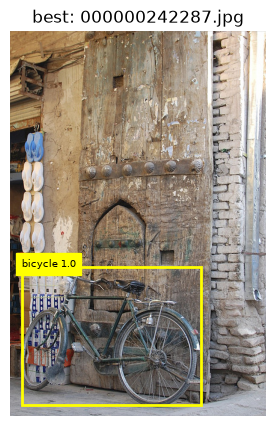

13 bicycles parked here.
saved results/worst.png


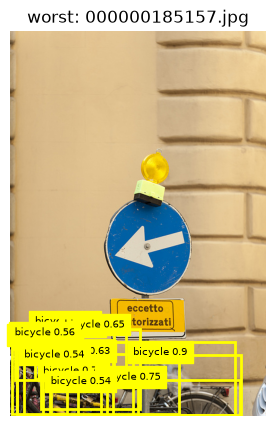

In [12]:
# The end result: my app on my best and my worst photo - saved for the slides
best, worst = "000000242287.jpg", "000000185157.jpg"   # best: 1 bike, counted right; worst: 6 COCO-labelled, 13 counted
for name, label in [(best, "best"), (worst, "worst")]:
    print(my_app(photos[name], label + ": " + name))
    save_result(label + ".png")
    plt.show()
# download_results()


## Photo credits

All photos come from the COCO dataset (cocodataset.org), validation set 2017, which collected them from Flickr. **Changes:** in this notebook and in `best.png` / `worst.png` the photos are made smaller and boxes and labels are drawn on them. These changed versions are shared under the same licence as each original.

| Photo | Title | Photographer | Licence | Original |
|---|---|---|---|---|
| 000000008899.jpg | 127 Henry Street, New York, NY | Zach Korb | [CC BY-NC 2.0](https://creativecommons.org/licenses/by-nc/2.0/) | [Flickr](https://www.flickr.com/photos/zkorb/7722123984/) |
| 000000101762.jpg | Untitled | thisisforever | [CC BY-NC-SA 2.0](https://creativecommons.org/licenses/by-nc-sa/2.0/) | [Flickr](https://www.flickr.com/photos/thisisforever/2135673297/) |
| 000000109055.jpg | Fort by wheels | hexion | [CC BY-NC-SA 2.0](https://creativecommons.org/licenses/by-nc-sa/2.0/) | [Flickr](https://www.flickr.com/photos/hexion/37248397/) |
| 000000135670.jpg | - | not recovered: the original Flickr page could not be retrieved | [CC BY-SA 2.0 (as recorded in the COCO dataset)](https://creativecommons.org/licenses/by-sa/2.0/) | page could not be retrieved ([lookup](https://www.flickr.com/photo.gne?id=3925803088)) |
| 000000164115.jpg | Surfboard Rack | David (randomcuriosity) | [CC BY-NC-SA 2.0](https://creativecommons.org/licenses/by-nc-sa/2.0/) | [Flickr](https://www.flickr.com/photos/randomcuriosity/2807365025/) |
| 000000185157.jpg | Street Signs | Jason Pier in DC | [CC BY-NC 2.0](https://creativecommons.org/licenses/by-nc/2.0/) | [Flickr](https://www.flickr.com/photos/jasonpier/5075371191/) |
| 000000242287.jpg | Old Door and a Bike | Jim Kelly (pthread1981) | [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/) | [Flickr](https://www.flickr.com/photos/pthread/4072194513/) |
| 000000274687.jpg | - | not recovered: the original Flickr page could not be retrieved | [CC BY-SA 2.0 (as recorded in the COCO dataset)](https://creativecommons.org/licenses/by-sa/2.0/) | page could not be retrieved ([lookup](https://www.flickr.com/photo.gne?id=4075988767)) |
| 000000426166.jpg | Blue Bike | Talbot Troy (Rusty Darbonne) | [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/) | [Flickr](https://www.flickr.com/photos/rustydarbonne/2319776213/) |